# **Market Basket Analysis for a College Canteen**
**Name:** Shlok Vij  
**PRN:** 23070521143  
**Section:** B

## Real-life application
This project helps a **college canteen** create smarter combos for students. It analyses past orders to discover which food and drink items are bought together. For example, it can identify whether students ordering a burger often add fries or iced coffee, and whether study-break orders commonly include cold coffee and a brownie.

The dataset below is a small, realistic **demonstration dataset created inside this notebook**, so no manual upload is needed. For a real deployment, replace it with anonymised canteen billing data.

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Total customer orders: 20

TOP ASSOCIATION RULES:
         Buy    Recommend  Support  Confidence  Lift
       Chips        Maggi     0.15        1.00  6.67
       Maggi        Chips     0.15        1.00  6.67
Garlic Bread        Pizza     0.15        1.00  5.00
       Pizza Garlic Bread     0.15        0.75  5.00
       Fries       Burger     0.25        1.00  3.33
      Burger        Fries     0.25        0.83  3.33
     Brownie       Cookie     0.10        0.50  2.50
      Cookie      Brownie     0.10        0.50  2.50
      Cookie       Coffee     0.20        1.00  2.00
      Coffee       Cookie     0.20        0.40  2.00

FORMULA EXAMPLE: Burger -> Fries
Support = 5/20 = 0.25
Confidence = 5/6 = 0.83
Lift = 0.83/(5/20) = 3.33

CUSTOMER HAS ORDERED: Burger
Recommend  Confidence  Lift
    Fries        0.83  3.33
     Cola        0.67  1.67
  Brownie        0.17  0.83
   Coffee        0.17  0.33


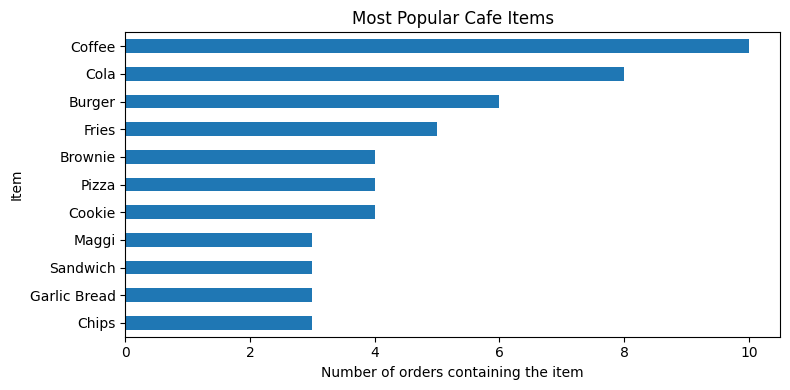

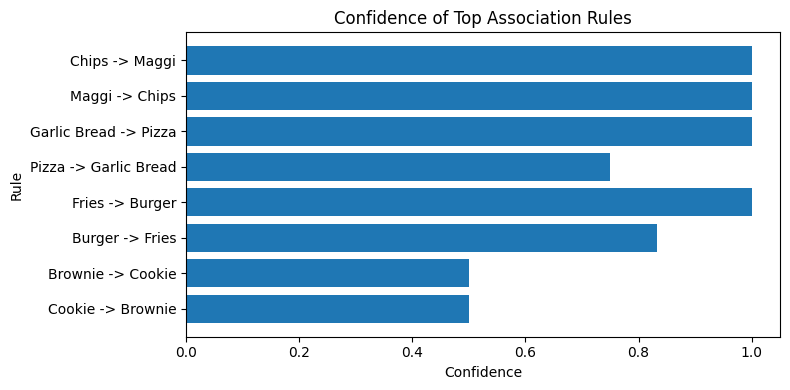

In [13]:
# SHLOK VIJ
# PRN: 23070521143
# MARKET BASKET ANALYSIS: CAFE COMBO RECOMMENDER

# Hide repeated Jupyter deprecation warnings in the output.
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations

# 1. DATASET
# Each list represents one cafe bill / customer order.
transactions = [
    ["Burger", "Fries", "Cola"],
    ["Burger", "Fries", "Cola"],
    ["Burger", "Fries", "Coffee"],
    ["Burger", "Cola"],
    ["Burger", "Fries", "Brownie"],
    ["Pizza", "Garlic Bread", "Cola"],
    ["Pizza", "Garlic Bread", "Cola"],
    ["Pizza", "Cola"],
    ["Pizza", "Garlic Bread", "Coffee"],
    ["Coffee", "Brownie", "Cookie"],
    ["Coffee", "Brownie"],
    ["Coffee", "Brownie", "Cookie"],
    ["Coffee", "Cookie"],
    ["Maggi", "Coffee", "Chips"],
    ["Maggi", "Chips"],
    ["Maggi", "Coffee", "Chips"],
    ["Sandwich", "Coffee", "Cookie"],
    ["Sandwich", "Coffee"],
    ["Sandwich", "Cola"],
    ["Burger", "Fries", "Cola"]
]

total_orders = len(transactions)
print("Total customer orders:", total_orders)

# 2. COUNT EACH ITEM
# Count the number of bills that contain each item.
items = sorted(set(item for order in transactions for item in order))
item_counts = {
    item: sum(item in order for order in transactions)
    for item in items
}

# 3. MARKET BASKET FORMULAS
# Support = orders containing both items / total orders
# Confidence(A -> B) = orders containing both / orders containing A
# Lift(A -> B) = confidence(A -> B) / support(B)

rules = []

# Only item pairs are checked, so the calculation stays small and fast.
for item_a, item_b in combinations(items, 2):
    both_count = sum(
        item_a in order and item_b in order
        for order in transactions
    )

    if both_count == 0:
        continue

    support = both_count / total_orders

    # Rule A -> B
    confidence_ab = both_count / item_counts[item_a]
    lift_ab = confidence_ab / (item_counts[item_b] / total_orders)

    rules.append([
        item_a, item_b, support, confidence_ab, lift_ab
    ])

    # Rule B -> A
    confidence_ba = both_count / item_counts[item_b]
    lift_ba = confidence_ba / (item_counts[item_a] / total_orders)

    rules.append([
        item_b, item_a, support, confidence_ba, lift_ba
    ])

rules_df = pd.DataFrame(
    rules,
    columns=["Buy", "Recommend", "Support", "Confidence", "Lift"]
)

# Display the top rules by lift.
rules_df = rules_df.sort_values(
    ["Lift", "Confidence"], ascending=False
).reset_index(drop=True)

print("\nTOP ASSOCIATION RULES:")
print(rules_df.head(10).round(2).to_string(index=False))

# 4. MANUAL EXAMPLE: BURGER -> FRIES
# These calculations show how the formulas work with real counts.
A, B = "Burger", "Fries"
count_a = item_counts[A]
count_b = item_counts[B]
count_both = sum(A in order and B in order for order in transactions)

support = count_both / total_orders
confidence = count_both / count_a
lift = confidence / (count_b / total_orders)

print("\nFORMULA EXAMPLE: Burger -> Fries")
print(f"Support = {count_both}/{total_orders} = {support:.2f}")
print(f"Confidence = {count_both}/{count_a} = {confidence:.2f}")
print(f"Lift = {confidence:.2f}/({count_b}/{total_orders}) = {lift:.2f}")

# 5. SIMPLE CAFE RECOMMENDATION
# Show which items are associated with a Burger order.
print("\nCUSTOMER HAS ORDERED: Burger")
burger_suggestions = rules_df[rules_df["Buy"] == "Burger"]
print(
    burger_suggestions[["Recommend", "Confidence", "Lift"]]
    .head(5).round(2).to_string(index=False)
)

# 6. GRAPH 1: MOST POPULAR ITEMS
plt.figure(figsize=(8, 4))
pd.Series(item_counts).sort_values().plot(kind="barh")
plt.title("Most Popular Cafe Items")
plt.xlabel("Number of orders containing the item")
plt.ylabel("Item")
plt.tight_layout()
plt.show()
plt.close()

# 7. GRAPH 2: CONFIDENCE OF TOP RULES
top_rules = rules_df.head(8).copy()
labels = top_rules["Buy"] + " -> " + top_rules["Recommend"]

plt.figure(figsize=(8, 4))
plt.barh(labels.iloc[::-1], top_rules["Confidence"].iloc[::-1])
plt.title("Confidence of Top Association Rules")
plt.xlabel("Confidence")
plt.ylabel("Rule")
plt.tight_layout()
plt.show()
plt.close()

# CONCLUSION:
# A cafe can use these patterns to suggest add-ons and create combo meals.
# This is demonstration data; real decisions require actual sales transactions.
